# S1 check: uncertainty method and the adopted $\beta$

This notebook backs up two statements the manuscript's Methods currently lack:

1. **Fit uncertainties come from a bootstrap over the 12 *sources*, not the 552 data points.**
   The points are not independent (NGC 4151 alone contributes 302), so naive least-squares errors are far too small.
2. **$\beta = 0.5$ is *adopted*, not fitted.** The x-axis $a_R L_X^{1/2}$ fixes it by construction.
   Section 5 fits $\beta$ freely to test whether the data support 0.5.

The data are loaded directly from `correlations.ipynb` (section 1), so any change you make there propagates here.
The bootstrap settings match the ones used for the numbers now quoted in the manuscript.

In [1]:
import json, contextlib, io, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

warnings.filterwarnings("ignore")

SOURCE_NB = Path("correlations.ipynb")   # your main notebook, same folder
LAST_DATA_CELL = 'df = pd.merge(df, n6814'  # data loading ends at the NGC 6814 merge
N_BOOT = 4000                             # matches the manuscript numbers
SEED = 1                                  # matches the manuscript numbers
XRBS = ["GROJ1655", "GX339", "XTEJ1118", "J1753", "MAXI J1820"]

## 1. Load the data from `correlations.ipynb`

This runs your notebook's code cells in order, up to and including the cell that merges NGC 6814 into `df`, and keeps the resulting variables.
Plotting cells after that point are not run.

In [2]:
def load_from_notebook(path, last_marker):
    nb = json.loads(Path(path).read_text())
    ns = {}
    for cell in nb["cells"]:
        if cell["cell_type"] != "code":
            continue
        src = "".join(cell["source"])
        # drop IPython magics such as %matplotlib inline
        code = "\n".join(l for l in src.splitlines() if not l.lstrip().startswith(("%", "!")))
        with contextlib.redirect_stdout(io.StringIO()):
            exec(code, ns)
        if last_marker in src:
            return ns
    raise RuntimeError(f"Could not find the cell containing {last_marker!r}")

ns = load_from_notebook(SOURCE_NB, LAST_DATA_CELL)
plt.rcParams.update({"text.usetex": False})   # the source notebook switches LaTeX rendering on

df = ns["df"].reset_index(drop=True)
df["population"] = np.where(df["Target"].isin(XRBS), "XRB", "AGN")
print(f"{len(df)} data points from {df['Target'].nunique()} sources")

552 data points from 12 sources


## 2. Why the 552 points are not independent

Each source contributes many points, and all points from one source share the same lag (so the same $a_R$), distance, inclination and black-hole mass.
A regression that treats them as 552 independent measurements overstates the information content.

In [3]:
counts = (df.groupby(["population", "Target"]).size()
            .rename("N points").reset_index()
            .sort_values("N points", ascending=False))
counts["share of sample"] = (counts["N points"] / len(df)).map("{:.1%}".format)
counts

,population,Target,N points,share of sample
3,AGN,NGC4151,302,54.7%
0,AGN,NGC2617,118,21.4%
11,XRB,XTEJ1118,53,9.6%
8,XRB,GX339,49,8.9%
1,AGN,NGC3516,7,1.3%
9,XRB,J1753,6,1.1%
7,XRB,GROJ1655,5,0.9%
4,AGN,NGC4395,3,0.5%
6,AGN,NGC6814,3,0.5%
10,XRB,MAXI J1820,3,0.5%


## 3. Naive least-squares errors vs a bootstrap over sources

Each bootstrap realisation draws 12 sources **with replacement** (so a source can appear twice or not at all) and refits using *all* points of the drawn sources.
The spread of the refitted slopes and intercepts is the uncertainty.
This keeps each source's points together, which is what makes it honest about the real number of independent systems.

In [4]:
def xy(d, cos_i=False):
    x = np.log10(d["sqrt(L_x) a"] * (d["cos_i"] if cos_i else 1.0)).to_numpy()
    y = np.log10(d["L_opt"]).to_numpy()
    return x, y

def source_bootstrap(targets, fit_rows, n_boot=N_BOOT, seed=SEED):
    # Resample whole sources with replacement; fit_rows(row_indices) returns a tuple of statistics.
    rng = np.random.default_rng(seed)
    sources = np.unique(targets)
    rows_of = {s: np.flatnonzero(targets == s) for s in sources}
    out = []
    for _ in range(n_boot):
        pick = rng.choice(sources, size=sources.size, replace=True)
        if np.unique(pick).size < 2:          # a slope needs at least two distinct sources
            continue
        out.append(fit_rows(np.concatenate([rows_of[s] for s in pick])))
    return np.array(out)

def slope_intercept(x, y):
    r = linregress(x, y)
    return r.slope, r.intercept

samples = {"Global": df,
           "XRB only": df[df["population"] == "XRB"].reset_index(drop=True),
           "AGN only": df[df["population"] == "AGN"].reset_index(drop=True)}

rows, boots = [], {}
for name, d in samples.items():
    targets = d["Target"].to_numpy()
    for use_cos_i in (False, True):
        x, y = xy(d, use_cos_i)
        r = linregress(x, y)
        bs = source_bootstrap(targets, lambda idx: slope_intercept(x[idx], y[idx]))
        boots[(name, use_cos_i)] = bs
        resid = y - (r.slope * x + r.intercept)
        rows.append({
            "sample": name, "cos i": "yes" if use_cos_i else "no",
            "points": len(d), "sources": d["Target"].nunique(),
            "slope": r.slope, "slope ± naive": r.stderr, "slope ± bootstrap": bs[:, 0].std(),
            "intercept": r.intercept, "int ± naive": r.intercept_stderr, "int ± bootstrap": bs[:, 1].std(),
            "R": r.rvalue, "scatter [dex]": np.std(resid, ddof=2),
        })

summary = pd.DataFrame(rows)
summary["underestimate (×)"] = summary["slope ± bootstrap"] / summary["slope ± naive"]
summary.round(3)

,sample,cos i,points,sources,slope,slope ± naive,slope ± bootstrap,intercept,int ± naive,int ± bootstrap,R,scatter [dex],underestimate (×)
0,Global,no,552,12,0.955,0.003,0.034,19.875,0.058,0.656,0.998,0.201,12.656
1,Global,yes,552,12,0.918,0.002,0.030,20.872,0.050,0.535,0.998,0.183,13.176
2,XRB only,no,116,5,1.131,0.033,0.222,17.153,0.519,3.335,0.954,0.245,6.664
3,XRB only,yes,116,5,0.955,0.022,0.175,20.329,0.327,2.548,0.972,0.191,8.120
4,AGN only,no,436,7,1.001,0.025,0.231,18.808,0.582,5.313,0.888,0.178,9.272
5,AGN only,yes,436,7,1.005,0.025,0.225,18.843,0.580,5.152,0.889,0.177,9.016


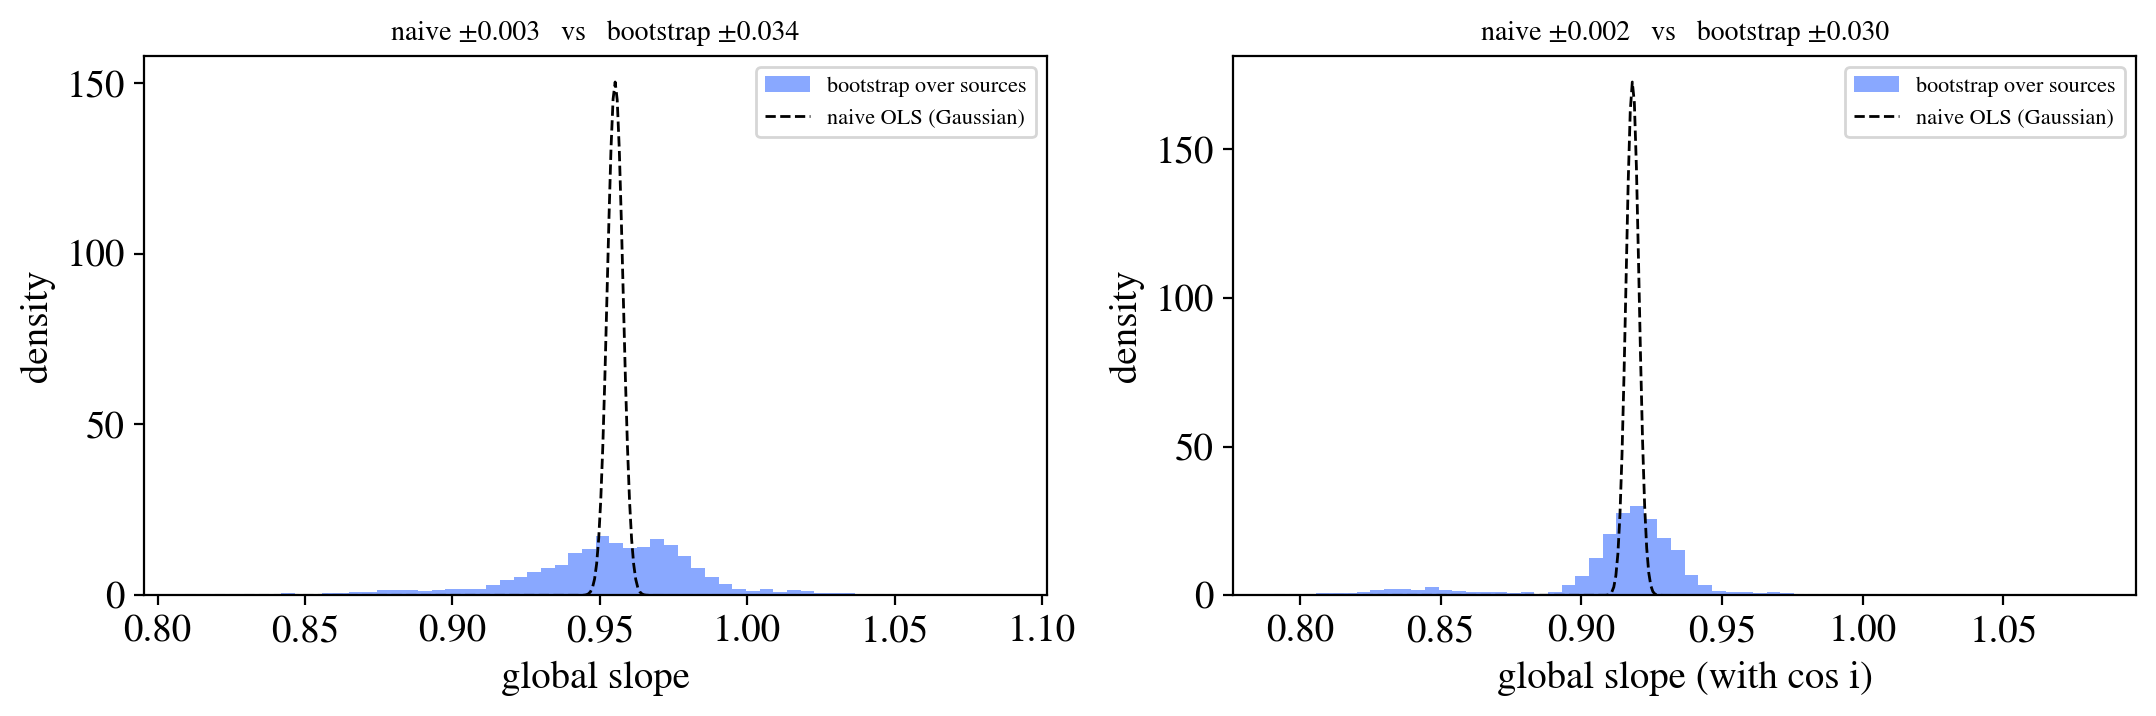

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, use_cos_i in zip(axes, (False, True)):
    bs = boots[("Global", use_cos_i)][:, 0]
    row = summary[(summary["sample"] == "Global") & (summary["cos i"] == ("yes" if use_cos_i else "no"))].iloc[0]
    ax.hist(bs, bins=60, density=True, color="#2962FF", alpha=0.55, label="bootstrap over sources")
    grid = np.linspace(bs.min(), bs.max(), 400)
    for sig, style, lab in ((row["slope ± naive"], "k--", "naive OLS (Gaussian)"),):
        ax.plot(grid, np.exp(-0.5 * ((grid - row["slope"]) / sig) ** 2) / (sig * np.sqrt(2 * np.pi)), style, lw=1, label=lab)
    ax.set_xlabel("global slope" + (" (with cos i)" if use_cos_i else ""))
    ax.set_ylabel("density")
    ax.set_title(f"naive ±{row['slope ± naive']:.3f}   vs   bootstrap ±{row['slope ± bootstrap']:.3f}", fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Leave-one-source-out check

Refit the global relation with each source removed in turn.
If no single source drives the slope, these values should stay within the bootstrap error.

In [6]:
x_all, y_all = xy(df)
base = linregress(x_all, y_all)
jk = []
for s in sorted(df["Target"].unique()):
    keep = df["Target"].to_numpy() != s
    r = linregress(x_all[keep], y_all[keep])
    jk.append({"removed": s, "points removed": int((~keep).sum()),
               "slope": r.slope, "Δslope": r.slope - base.slope, "intercept": r.intercept})
jk = pd.DataFrame(jk)
print(f"Full-sample slope {base.slope:.3f}; leave-one-out range {jk.slope.min():.3f} to {jk.slope.max():.3f}")
jk.round(3)

Full-sample slope 0.955; leave-one-out range 0.938 to 0.975


,removed,points removed,slope,Δslope,intercept
0,GROJ1655,5,0.952,-0.004,19.958
1,GX339,49,0.975,0.020,19.398
2,J1753,6,0.954,-0.001,19.900
3,MAXI J1820,3,0.955,-0.000,19.885
4,NGC2617,118,0.947,-0.009,20.013
5,NGC3516,7,0.957,0.002,19.851
6,NGC4051,1,0.955,0.000,19.874
7,NGC4151,302,0.966,0.011,19.708
8,NGC4395,3,0.955,0.000,19.867
9,NGC4593,2,0.955,0.000,19.874


## 5. Is $\beta = 0.5$ supported? A free two-exponent fit

The manuscript's fit fixes the ratio of exponents:
$\log L_V = m\,(0.5\log L_X + \log a_R) + c$, so the effective $L_X$ exponent is $0.5m$ and the $a_R$ exponent is $m$.

Here both exponents are free:
$$\log L_V = \beta\,\log L_X + \gamma\,\log a_R + c .$$
If the adopted scaling is right, $\beta$ should be consistent with 0.5 (more precisely, with $0.5m$), and $\gamma$ with $m$.
$a_R$ is the lag in hours, as in Eq. 5.

In [7]:
def free_fit(lv, lx, la):
    X = np.column_stack([np.ones_like(lv), lx, la])
    coef, *_ = np.linalg.lstsq(X, lv, rcond=None)
    resid = lv - X @ coef
    dof = len(lv) - X.shape[1]
    cov = (resid @ resid / dof) * np.linalg.inv(X.T @ X)
    return coef, np.sqrt(np.diag(cov)), np.std(resid, ddof=X.shape[1])

targets = df["Target"].to_numpy()
lv = np.log10(df["L_opt"].to_numpy())
lx = np.log10(df["L_x"].to_numpy())

beta_rows, beta_boots = [], {}
for use_cos_i in (False, True):
    la = np.log10((df["Lag"] * (df["cos_i"] if use_cos_i else 1.0)).to_numpy())
    coef, err_naive, scat = free_fit(lv, lx, la)
    bs = source_bootstrap(targets, lambda idx: tuple(free_fit(lv[idx], lx[idx], la[idx])[0]))
    beta_boots[use_cos_i] = bs
    m = linregress(0.5 * lx + la, lv).slope          # constrained (manuscript) fit
    b_sd, g_sd = bs[:, 1].std(), bs[:, 2].std()
    beta_rows.append({
        "cos i": "yes" if use_cos_i else "no",
        "beta (free)": coef[1], "± naive": err_naive[1], "± bootstrap": b_sd,
        "gamma (free)": coef[2], "± naive ": err_naive[2], "± bootstrap ": g_sd,
        "constrained: beta = 0.5m": 0.5 * m, "constrained: gamma = m": m,
        "beta vs 0.5 [σ]": (coef[1] - 0.5) / b_sd,
        "corr(beta, gamma)": np.corrcoef(bs[:, 1], bs[:, 2])[0, 1],
        "scatter free [dex]": scat,
    })

print(f"corr(log L_X, log a_R) across the sample = {np.corrcoef(lx, np.log10(df['Lag']))[0, 1]:.3f}")
beta_table = pd.DataFrame(beta_rows)
beta_table.round(3).T

corr(log L_X, log a_R) across the sample = 0.987


,0,1
cos i,no,yes
beta (free),0.532,0.485
± naive,0.019,0.018
± bootstrap,0.125,0.121
gamma (free),0.868,0.88
± naive,0.03,0.026
± bootstrap,0.198,0.177
constrained: beta = 0.5m,0.478,0.459
constrained: gamma = m,0.955,0.918
beta vs 0.5 [σ],0.258,-0.128


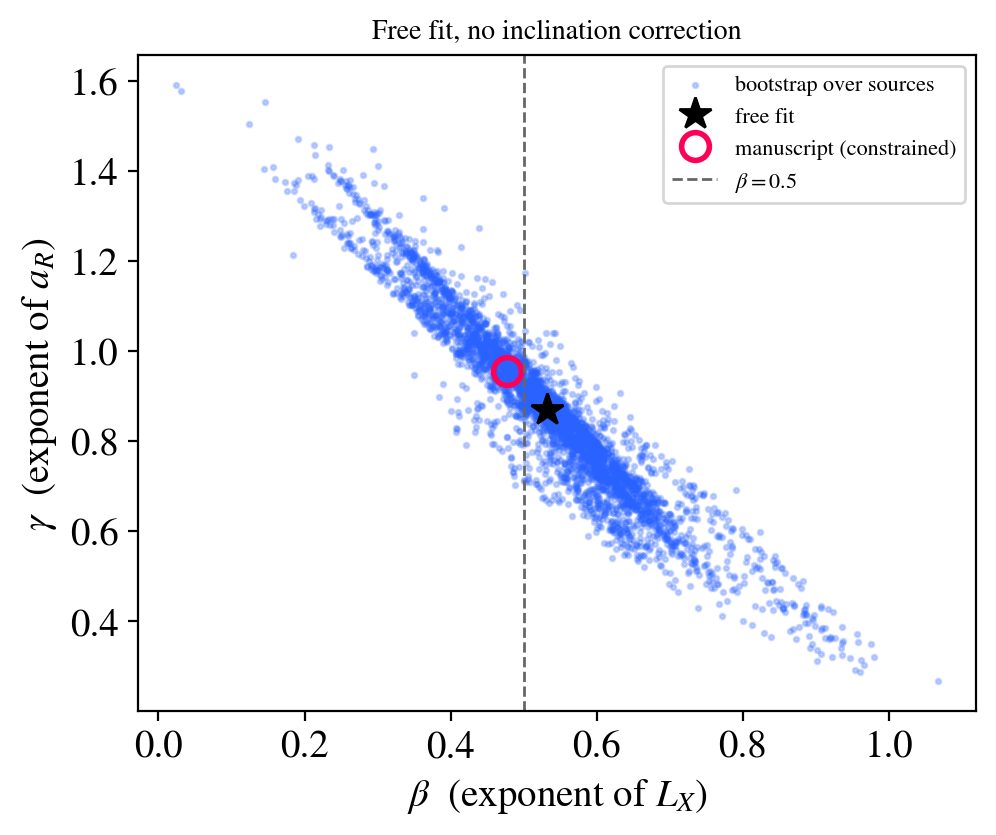

In [8]:
bs = beta_boots[False]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.scatter(bs[:, 1], bs[:, 2], s=3, alpha=0.25, color="#2962FF", label="bootstrap over sources")
row = beta_table.iloc[0]
ax.plot(row["beta (free)"], row["gamma (free)"], "k*", ms=12, label="free fit")
ax.plot(row["constrained: beta = 0.5m"], row["constrained: gamma = m"], "o", mfc="none", mec="#FF0059", ms=10, mew=2,
        label="manuscript (constrained)")
ax.axvline(0.5, color="0.4", ls="--", lw=1, label=r"$\beta = 0.5$")
ax.set_xlabel(r"$\beta$  (exponent of $L_X$)")
ax.set_ylabel(r"$\gamma$  (exponent of $a_R$)")
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Free fit, no inclination correction", fontsize=10)
plt.tight_layout()
plt.show()

## 6. Is the bootstrap error stable?

Bootstrap errors carry their own sampling noise.
Re-running the global fit with different seeds shows how many digits are meaningful.

In [9]:
x_all, y_all = xy(df)
stab = []
for seed in (1, 2, 3, 4, 5):
    bs = source_bootstrap(targets, lambda idx: slope_intercept(x_all[idx], y_all[idx]), seed=seed)
    stab.append({"seed": seed, "slope ± bootstrap": bs[:, 0].std(), "int ± bootstrap": bs[:, 1].std()})
stab = pd.DataFrame(stab)
print(f"slope error across seeds: {stab['slope ± bootstrap'].min():.3f} to {stab['slope ± bootstrap'].max():.3f}")
stab.round(4)

slope error across seeds: 0.032 to 0.034


,seed,slope ± bootstrap,int ± bootstrap
0,1,0.0336,0.6562
1,2,0.0323,0.6303
2,3,0.0341,0.6785
3,4,0.0338,0.6618
4,5,0.0329,0.6459


## 7. Paste-ready Methods text

Generated from the numbers above, so it stays correct if the data change.
Suggested place: right after Eq. 5 in Section 4.1.

In [10]:
g0 = summary[(summary["sample"] == "Global") & (summary["cos i"] == "no")].iloc[0]
g1 = summary[(summary["sample"] == "Global") & (summary["cos i"] == "yes")].iloc[0]
b0 = beta_table.iloc[0]
largest = counts.iloc[0]
rho_lx_la = np.corrcoef(lx, np.log10(df["Lag"]))[0, 1]

text = (
    f"Uncertainties on the fit parameters were estimated by bootstrap resampling of the "
    f"{df['Target'].nunique()} sources rather than the individual measurements, because the "
    f"{len(df)} data points are drawn from only {df['Target'].nunique()} independent systems "
    f"(e.g., {largest['Target'].replace('NGC', 'NGC~')} alone contributes {largest['N points']} points); "
    f"least-squares errors that treat every point as independent underestimate the slope uncertainty "
    f"by a factor of $\\sim${g0['underestimate (×)']:.0f}. "
    f"Throughout, we adopt $\\beta = 0.5$ rather than fitting it, so the relation is tested as a "
    f"one-parameter scaling in $a_R L_X^{{0.5}}$. As a check, fitting "
    f"$\\log L_V = \\beta \\log L_X + \\gamma \\log a_R + c$ with both exponents free yields "
    f"$\\beta = {b0['beta (free)']:.2f} \\pm {b0['± bootstrap']:.2f}$ and "
    f"$\\gamma = {b0['gamma (free)']:.2f} \\pm {b0['± bootstrap ']:.2f}$, consistent with the adopted scaling "
    f"($\\beta = {b0['constrained: beta = 0.5m']:.2f}$, $\\gamma = {b0['constrained: gamma = m']:.2f}$ for the best-fit slope); "
    f"the two exponents are strongly anti-correlated ($\\rho = {b0['corr(beta, gamma)']:.2f}$) "
    f"because $\\log L_X$ and $\\log a_R$ are themselves correlated across the sample ($r = {rho_lx_la:.2f}$)."
)
print(text)
print()
print(f"Numbers already in the manuscript, for comparison: "
      f"slope {g0['slope']:.3f} ± {g0['slope ± bootstrap']:.3f} (no cos i), "
      f"{g1['slope']:.3f} ± {g1['slope ± bootstrap']:.3f} (cos i).")

Uncertainties on the fit parameters were estimated by bootstrap resampling of the 12 sources rather than the individual measurements, because the 552 data points are drawn from only 12 independent systems (e.g., NGC~4151 alone contributes 302 points); least-squares errors that treat every point as independent underestimate the slope uncertainty by a factor of $\sim$13. Throughout, we adopt $\beta = 0.5$ rather than fitting it, so the relation is tested as a one-parameter scaling in $a_R L_X^{0.5}$. As a check, fitting $\log L_V = \beta \log L_X + \gamma \log a_R + c$ with both exponents free yields $\beta = 0.53 \pm 0.13$ and $\gamma = 0.87 \pm 0.20$, consistent with the adopted scaling ($\beta = 0.48$, $\gamma = 0.96$ for the best-fit slope); the two exponents are strongly anti-correlated ($\rho = -0.95$) because $\log L_X$ and $\log a_R$ are themselves correlated across the sample ($r = 0.99$).

Numbers already in the manuscript, for comparison: slope 0.955 ± 0.034 (no cos i), 0.918 

## 8. The inclination-corrected relation, $L_V$ vs $a_R \cos i\, L_X^{1/2}$

The same checks as for the main relation, applied to the inclination-corrected fit (Eq. 6, Fig. 2):
the source bootstrap, leave-one-source-out, seed stability and the free-exponent fit.
Section 8.5 then tests the claim the manuscript makes about this fit: that adding $\cos i$ *reduces the scatter*.

In [11]:
side = (summary[summary["sample"] == "Global"]
        .set_index("cos i")[["slope", "slope ± naive", "slope ± bootstrap", "underestimate (×)",
                              "intercept", "int ± naive", "int ± bootstrap", "R", "scatter [dex]"]]
        .rename(index={"no": "uncorrected", "yes": "cos i corrected"}).T)
side.round(3)

cos i,uncorrected,cos i corrected
slope,0.955,0.918
slope ± naive,0.003,0.002
slope ± bootstrap,0.034,0.030
underestimate (×),12.656,13.176
intercept,19.875,20.872
int ± naive,0.058,0.050
int ± bootstrap,0.656,0.535
R,0.998,0.998
scatter [dex],0.201,0.183


### 8.1 Leave-one-source-out (cos *i* corrected)

In [12]:
xc, yc = xy(df, cos_i=True)
base_c = linregress(xc, yc)
jk_c = []
for s in sorted(df["Target"].unique()):
    keep = df["Target"].to_numpy() != s
    r = linregress(xc[keep], yc[keep])
    jk_c.append({"removed": s, "points removed": int((~keep).sum()), "slope": r.slope,
                 "Δslope": r.slope - base_c.slope, "intercept": r.intercept})
jk_c = pd.DataFrame(jk_c)
print(f"Full-sample slope {base_c.slope:.3f}; leave-one-out range {jk_c.slope.min():.3f} to {jk_c.slope.max():.3f} "
      f"(largest shift {jk_c['Δslope'].abs().max():.3f}, removing {jk_c.loc[jk_c['Δslope'].abs().idxmax(), 'removed']})")
jk_c.round(3)

Full-sample slope 0.918; leave-one-out range 0.910 to 0.928 (largest shift 0.009, removing NGC4151)


,removed,points removed,slope,Δslope,intercept
0,GROJ1655,5,0.915,-0.003,20.949
1,GX339,49,0.926,0.008,20.679
2,J1753,6,0.919,0.001,20.860
3,MAXI J1820,3,0.918,-0.000,20.875
4,NGC2617,118,0.910,-0.008,21.005
5,NGC3516,7,0.920,0.002,20.848
6,NGC4051,1,0.918,0.000,20.872
7,NGC4151,302,0.928,0.009,20.734
8,NGC4395,3,0.918,0.000,20.869
9,NGC4593,2,0.918,0.000,20.871


### 8.2 Seed stability (cos *i* corrected)

In [13]:
stab_c = []
for seed in (1, 2, 3, 4, 5):
    bs = source_bootstrap(targets, lambda idx: slope_intercept(xc[idx], yc[idx]), seed=seed)
    stab_c.append({"seed": seed, "slope ± bootstrap": bs[:, 0].std(), "int ± bootstrap": bs[:, 1].std()})
stab_c = pd.DataFrame(stab_c)
print(f"slope error across seeds: {stab_c['slope ± bootstrap'].min():.3f} to {stab_c['slope ± bootstrap'].max():.3f}")
stab_c.round(4)

slope error across seeds: 0.029 to 0.031


,seed,slope ± bootstrap,int ± bootstrap
0,1,0.0305,0.5345
1,2,0.0291,0.5069
2,3,0.0309,0.5640
3,4,0.0303,0.5326
4,5,0.0294,0.5158


### 8.3 Free-exponent fit (cos *i* corrected)

$\log L_V = \beta \log L_X + \gamma \log(a_R \cos i) + c$, compared with the constrained fit ($\beta = 0.5m$, $\gamma = m$).

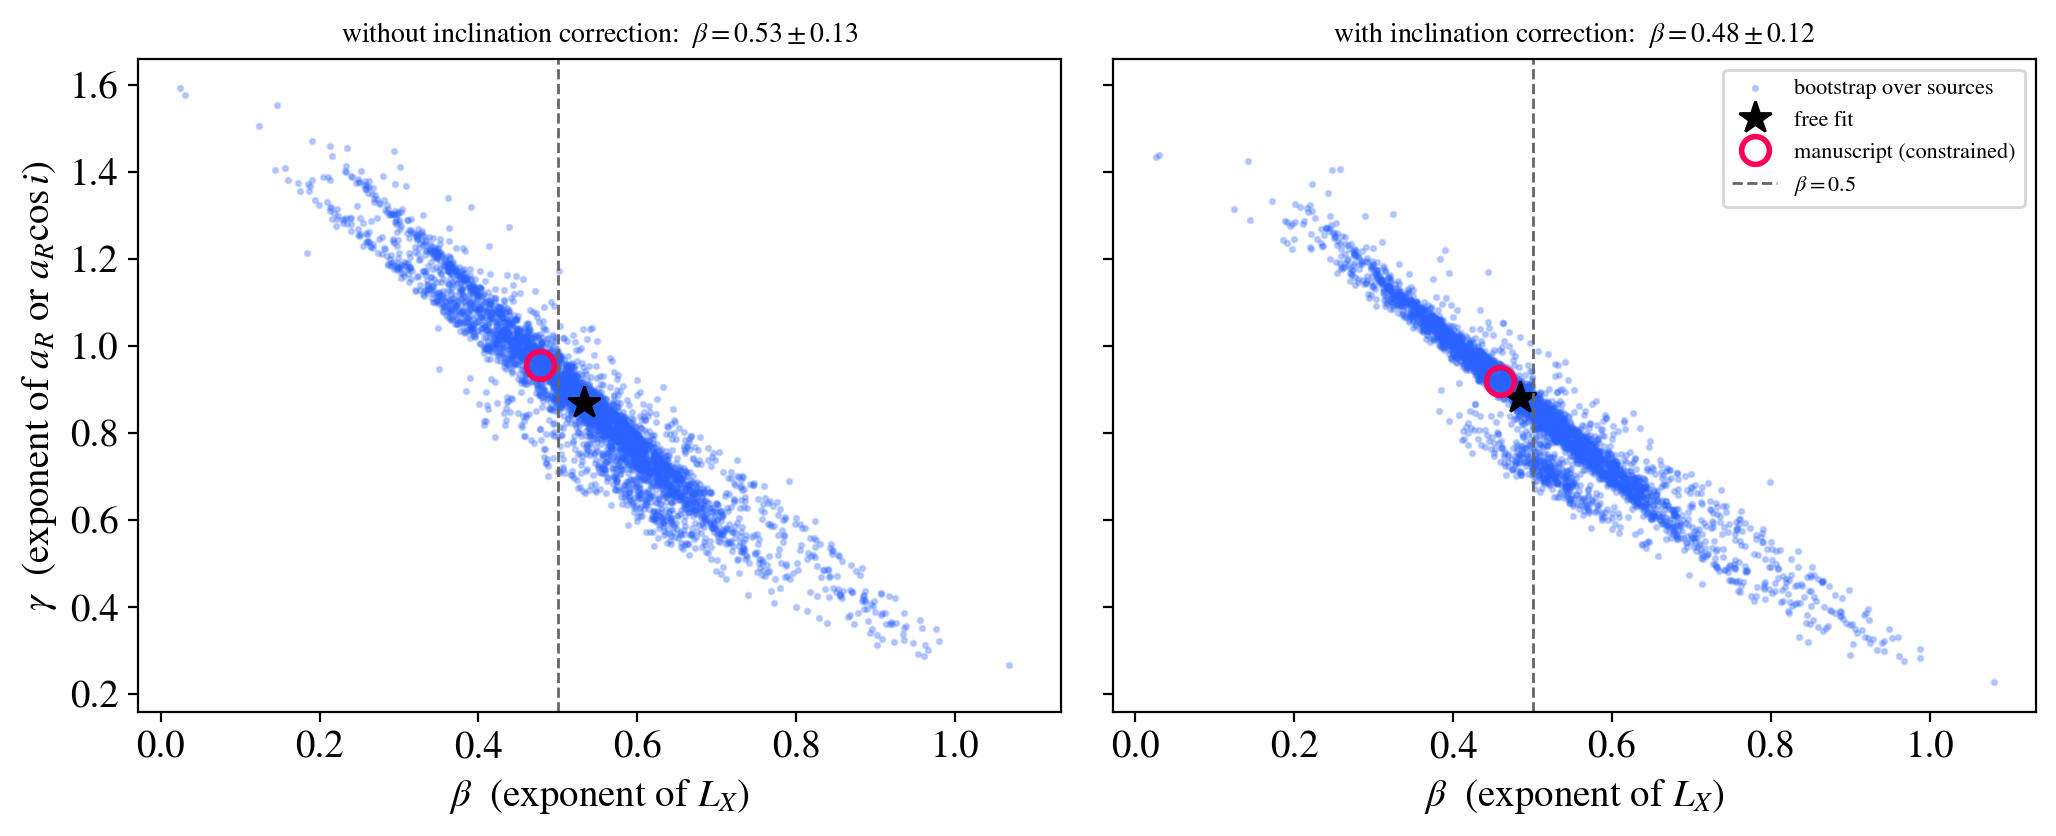

cos i,uncorrected,cos i corrected
beta (free),0.532,0.485
± naive,0.019,0.018
± bootstrap,0.125,0.121
gamma (free),0.868,0.880
± naive,0.030,0.026
± bootstrap,0.198,0.177
constrained: beta = 0.5m,0.478,0.459
constrained: gamma = m,0.955,0.918
beta vs 0.5 [σ],0.258,-0.128
"corr(beta, gamma)",-0.952,-0.955


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), sharex=True, sharey=True)
for ax, use_cos_i in zip(axes, (False, True)):
    bs = beta_boots[use_cos_i]
    row = beta_table.iloc[int(use_cos_i)]
    ax.scatter(bs[:, 1], bs[:, 2], s=3, alpha=0.25, color="#2962FF", label="bootstrap over sources")
    ax.plot(row["beta (free)"], row["gamma (free)"], "k*", ms=12, label="free fit")
    ax.plot(row["constrained: beta = 0.5m"], row["constrained: gamma = m"], "o", mfc="none", mec="#FF0059",
            ms=10, mew=2, label="manuscript (constrained)")
    ax.axvline(0.5, color="0.4", ls="--", lw=1, label=r"$\beta = 0.5$")
    ax.set_xlabel(r"$\beta$  (exponent of $L_X$)")
    ax.set_title(("with" if use_cos_i else "without") + " inclination correction:  "
                 + rf"$\beta = {row['beta (free)']:.2f} \pm {row['± bootstrap']:.2f}$", fontsize=10)
axes[0].set_ylabel(r"$\gamma$  (exponent of $a_R$ or $a_R\cos i$)")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()
beta_table.set_index("cos i").rename(index={"no": "uncorrected", "yes": "cos i corrected"}).T.round(3)

### 8.4 Does the cos *i* correction really reduce the scatter?

The manuscript says the total scatter drops from 0.201 to 0.183 dex, and the intrinsic scatter from 0.145 to 0.128 dex.
Two tests, both respecting that there are only twelve independent sources:

* **Paired source bootstrap.** Each realisation draws the same resampled set of sources for *both* fits, so the difference in scatter is measured on identical data. If the reduction is real, it should appear in most realisations.
* **Permutation test.** Shuffle the twelve measured $\cos i$ values among the twelve sources and refit. If the true inclinations matter, the real assignment should beat almost all random ones. Any per-source multiplicative factor gives the fit extra freedom, so some reduction is expected even by chance; this test measures how much.

The intrinsic scatter is the extra scatter needed, on top of the lag uncertainties, to make the reduced $\chi^2$ equal 1. These are the same lag errors used for the manuscript's 0.145 and 0.128 dex.

In [15]:
from scipy.optimize import brentq

# XTE J1118+480: +1.55/-2.45 s (Hynes+03 N V response, 1-5 s), symmetrised to 2.0 s
LAG_FRAC_ERR = {  # fractional lag uncertainty per source (asymmetric errors symmetrised), from Tables 1-2
    "GROJ1655": 2.2 / 19.3, "GX339": 4.0 / 10, "XTEJ1118": 2.0 / 3.45, "J1753": 0.5 / 1.0, "MAXI J1820": 1.6 / 4.1,
    "NGC4593": 0.41 / 0.907, "NGC4151": 0.475 / 1.30, "NGC3516": 0.845 / 2.6, "NGC4051": 0.65 / 1.2,
    "NGC2617": 0.845 / 2.47, "NGC4395": 49.0 / 788, "NGC6814": 1.15 / 1.9,
}
sig_logx = np.array([LAG_FRAC_ERR[t] for t in targets]) / np.log(10)
xu, yu = xy(df, cos_i=False)

def scatters(x, y, sx):
    r = linregress(x, y)
    res = y - (r.slope * x + r.intercept)
    dof = len(x) - 2
    sig = np.abs(r.slope) * sx
    f = lambda s: np.sum(res**2 / (sig**2 + s**2)) / dof - 1.0
    intrinsic = brentq(f, 1e-6, 5.0) if f(1e-6) > 0 else 0.0
    return np.std(res, ddof=2), intrinsic

tot_u, int_u = scatters(xu, yu, sig_logx)
tot_c, int_c = scatters(xc, yc, sig_logx)
print(f"full sample: total {tot_u:.3f} -> {tot_c:.3f} dex,  intrinsic {int_u:.3f} -> {int_c:.3f} dex")

paired = source_bootstrap(targets, lambda idx: (*scatters(xu[idx], yu[idx], sig_logx[idx]),
                                                *scatters(xc[idx], yc[idx], sig_logx[idx])))
d_tot = paired[:, 0] - paired[:, 2]      # > 0 means cos i reduced the total scatter
d_int = paired[:, 1] - paired[:, 3]
for name, d in (("total", d_tot), ("intrinsic", d_int)):
    lo, hi = np.percentile(d, [16, 84])
    print(f"paired bootstrap, {name:9s} scatter reduction: median {np.median(d):+.3f} dex, "
          f"68% interval [{lo:+.3f}, {hi:+.3f}], reduced in {np.mean(d > 0):.0%} of realisations")

full sample: total 0.201 -> 0.183 dex,  intrinsic 0.143 -> 0.127 dex


paired bootstrap, total     scatter reduction: median +0.015 dex, 68% interval [-0.003, +0.036], reduced in 75% of realisations
paired bootstrap, intrinsic scatter reduction: median +0.015 dex, 68% interval [-0.008, +0.037], reduced in 71% of realisations


true cos i assignment: total scatter 0.183 dex (uncorrected 0.201)
random reassignments:  median 0.244, 5th percentile 0.170
fraction of random assignments that do at least as well: p = 0.102


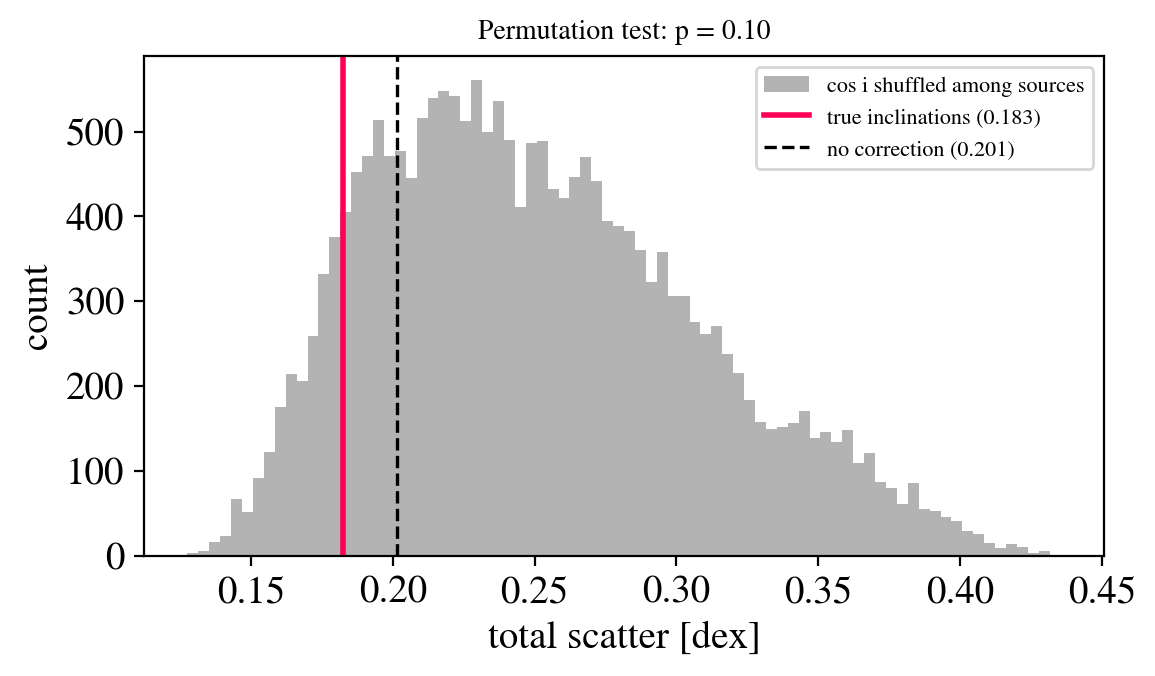

In [16]:
rng = np.random.default_rng(0)
src = np.array(sorted(df["Target"].unique()))
cos_by_src = np.array([df.loc[df["Target"] == s, "cos_i"].iloc[0] for s in src])
rows_of = {s: np.flatnonzero(targets == s) for s in src}
base_x = np.log10(df["sqrt(L_x) a"].to_numpy())

N_PERM = 20000
perm_tot = np.empty(N_PERM)
for k in range(N_PERM):
    ci = np.empty(len(df))
    for s, v in zip(src, rng.permutation(cos_by_src)):
        ci[rows_of[s]] = v
    x = base_x + np.log10(ci)
    r = linregress(x, yu)
    perm_tot[k] = np.std(yu - (r.slope * x + r.intercept), ddof=2)

p_value = np.mean(perm_tot <= tot_c)
print(f"true cos i assignment: total scatter {tot_c:.3f} dex (uncorrected {tot_u:.3f})")
print(f"random reassignments:  median {np.median(perm_tot):.3f}, 5th percentile {np.percentile(perm_tot, 5):.3f}")
print(f"fraction of random assignments that do at least as well: p = {p_value:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(perm_tot, bins=80, color="0.7", label="cos i shuffled among sources")
ax.axvline(tot_c, color="#FF0059", lw=2, label=f"true inclinations ({tot_c:.3f})")
ax.axvline(tot_u, color="k", ls="--", lw=1.2, label=f"no correction ({tot_u:.3f})")
ax.set_xlabel("total scatter [dex]")
ax.set_ylabel("count")
ax.set_title(f"Permutation test: p = {p_value:.2f}", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 8.5 Paste-ready text for the inclination-corrected fit

Generated from the numbers above. Suggested place: Section 4.2, in place of the sentence that reports the slope and scatter.

In [17]:
gc = summary[(summary["sample"] == "Global") & (summary["cos i"] == "yes")].iloc[0]
bc = beta_table.iloc[1]
text_c = (
    f"With the inclination correction, the best-fit slope is ${gc['slope']:.3f} \\pm {gc['slope ± bootstrap']:.3f}$ "
    f"(bootstrap over sources), and removing any single source changes it by at most {jk_c['Δslope'].abs().max():.2f}. "
    f"Fitting the exponents freely gives $\\beta = {bc['beta (free)']:.2f} \\pm {bc['± bootstrap']:.2f}$, again consistent with 0.5. "
    f"The total scatter decreases from ${tot_u:.3f}$ to ${tot_c:.3f}$\\,dex and the intrinsic scatter from ${int_u:.3f}$ to ${int_c:.3f}$\\,dex. "
    f"This reduction appears in {np.mean(d_tot > 0):.0%} of bootstrap realisations, "
    f"but randomly reassigning the twelve measured $\\cos i$ values among the sources yields a scatter at least as small "
    f"in {p_value:.0%} of trials, so with twelve independent systems the improvement is suggestive rather than decisive."
)
print(text_c)

With the inclination correction, the best-fit slope is $0.918 \pm 0.030$ (bootstrap over sources), and removing any single source changes it by at most 0.01. Fitting the exponents freely gives $\beta = 0.48 \pm 0.12$, again consistent with 0.5. The total scatter decreases from $0.201$ to $0.183$\,dex and the intrinsic scatter from $0.143$ to $0.127$\,dex. This reduction appears in 75% of bootstrap realisations, but randomly reassigning the twelve measured $\cos i$ values among the sources yields a scatter at least as small in 10% of trials, so with twelve independent systems the improvement is suggestive rather than decisive.
